# Block 6. Past fire cases

What did the satellites record for fires we know happened, and does the harmonized calendar flag them?
Plan: `docs/eda-plan.md`, block 6. Results: `docs/findings/06-case-studies.md`.

Rows: `harmonized/hotspots_kept.parquet` (quality filter of block 1, region corrected).
Calendar: `harmonized/cells_daily.parquet` (VIIRS-equivalent hotspots). Days are `burn_date`.

In [1]:
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore", category=DeprecationWarning)  # duckdb -> pandas noise
pd.set_option("display.width", 220, "display.max_columns", None, "display.max_colwidth", 60)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "NASA_Data_Sources").is_dir())
H = ROOT / "NASA_Data_Sources" / "processed" / "harmonized"
con = duckdb.connect()
con.execute("SET TimeZone='UTC'")
con.execute(f"CREATE VIEW h AS SELECT * FROM read_parquet('{H}/hotspots_kept.parquet')")
con.execute(f"CREATE VIEW c AS SELECT * FROM read_parquet('{H}/cells_daily.parquet')")


def q(sql: str) -> pd.DataFrame:
    return con.execute(sql).df()

## 6.1 Case register

An area is a box (west, south, east, north) or a list of regions. `reported_start` is the local
date the sources give for the start of the fire; it is empty when the sources only give a month
or a season. `months` are the calendar months checked in 6.3.

In [2]:
CASES = [
    dict(key="valparaiso_2024", name="Valparaíso and Viña del Mar, Feb 2024", country="Chile",
         box=(-71.70, -33.25, -71.30, -32.95), window=("2024-02-01", "2024-02-07"),
         reported_start="2024-02-02", months=[(2024, 2)],
         note="Started around midday near Lago Peñuelas; CONAF first attack at 12:31 local"),
    dict(key="centre_south_2023", name="Ñuble, Biobío and La Araucanía, Feb 2023", country="Chile",
         regions=["Región de Ñuble", "Región del Bío-Bío", "Región de La Araucanía"],
         window=("2023-01-30", "2023-02-20"), reported_start=None, months=[(2023, 2)]),
    dict(key="chile_2017", name="Central Chile, Jan 2017", country="Chile",
         regions=["Región del Libertador Bernardo O'Higgins", "Región del Maule", "Región de Ñuble", "Región del Bío-Bío"],
         window=("2017-01-10", "2017-02-05"), reported_start=None, months=[(2017, 1)]),
    dict(key="puerto_patriada_2026", name="Puerto Patriada, Chubut, Jan-Feb 2026", country="Argentina",
         box=(-71.90, -42.50, -71.20, -41.80), window=("2026-01-05", "2026-02-14"),
         reported_start="2026-01-05", months=[(2026, 1), (2026, 2)],
         note="The window starts on the reported day: 11 hotspots on 3-4 January sit at one spot "
              "25 km south-west of the main fire, a separate small fire"),
    dict(key="cordoba_2024", name="Córdoba, Sep 2024", country="Argentina", regions=["Córdoba"],
         window=("2024-09-01", "2024-09-30"), reported_start=None, months=[(2024, 9)]),
    dict(key="corrientes_2022", name="Corrientes, Jan-Feb 2022", country="Argentina", regions=["Corrientes"],
         window=("2022-01-01", "2022-02-28"), reported_start=None, months=[(2022, 1), (2022, 2)]),
    dict(key="chilecito_2026", name="Chilecito, La Rioja, Jul 2026", country="Argentina",
         box=(-67.90, -29.50, -67.20, -28.90), window=("2026-07-01", "2026-07-31"),
         reported_start=None, months=[(2026, 7)]),
    # Before Suomi-NPP (first data on 2012-01-20): only MODIS saw these.
    dict(key="torres_del_paine_2011", name="Torres del Paine, Dec 2011 - Jan 2012", country="Chile",
         box=(-73.40, -51.35, -72.50, -50.75), window=("2011-12-26", "2012-01-19"),
         reported_start="2011-12-27", months=[(2011, 12), (2012, 1)]),
    dict(key="parana_delta_2008", name="Paraná Delta, Apr 2008", country="Argentina",
         box=(-60.90, -34.40, -58.40, -32.40), window=("2008-04-01", "2008-04-30"),
         reported_start=None, months=[(2008, 4)]),
]


def area_sql(case, lat="latitude", lon="longitude", size=0.0):
    """SQL condition for the case area. With size > 0 it selects the cells that touch a box."""
    if "box" in case:
        w, s, e, n = case["box"]
        return f"{lon} < {e} AND {lon} + {size} > {w} AND {lat} < {n} AND {lat} + {size} > {s}"
    names = ", ".join("'" + r.replace("'", "''") + "'" for r in case["regions"])
    return f"country = '{case['country']}' AND admin1 IN ({names})"


pd.DataFrame([{"case": c["name"], "area": "box " + str(c["box"]) if "box" in c else ", ".join(c["regions"]),
               "window": " to ".join(c["window"]), "reported_start": c["reported_start"] or ""} for c in CASES])

,case,area,window,reported_start
0,"Valparaíso and Viña del Mar, Feb 2024","box (-71.7, -33.25, -71.3, -32.95)",2024-02-01 to 2024-02-07,2024-02-02
1,"Ñuble, Biobío and La Araucanía, Feb 2023","Región de Ñuble, Región del Bío-Bío, Región de La Araucanía",2023-01-30 to 2023-02-20,
2,"Central Chile, Jan 2017","Región del Libertador Bernardo O'Higgins, Región del Mau...",2017-01-10 to 2017-02-05,
3,"Puerto Patriada, Chubut, Jan-Feb 2026","box (-71.9, -42.5, -71.2, -41.8)",2026-01-05 to 2026-02-14,2026-01-05
4,"Córdoba, Sep 2024",Córdoba,2024-09-01 to 2024-09-30,
5,"Corrientes, Jan-Feb 2022",Corrientes,2022-01-01 to 2022-02-28,
6,"Chilecito, La Rioja, Jul 2026","box (-67.9, -29.5, -67.2, -28.9)",2026-07-01 to 2026-07-31,
7,"Torres del Paine, Dec 2011 - Jan 2012","box (-73.4, -51.35, -72.5, -50.75)",2011-12-26 to 2012-01-19,2011-12-27
8,"Paraná Delta, Apr 2008","box (-60.9, -34.4, -58.4, -32.4)",2008-04-01 to 2008-04-30,


## 6.2 What each satellite recorded

Hotspots per satellite inside the window, the first detection, the peak day, and the share of
provisional (NRT) rows.

In [3]:
rows = []
for case in CASES:
    a, (d0, d1) = area_sql(case), case["window"]
    r = q(f"""
        SELECT count(*) AS hotspots,
               count(*) FILTER (WHERE instrument = 'MODIS') AS modis,
               count(*) FILTER (WHERE satellite = 'Terra') AS terra,
               count(*) FILTER (WHERE satellite = 'Aqua') AS aqua,
               count(*) FILTER (WHERE satellite = 'Suomi-NPP') AS snpp,
               count(*) FILTER (WHERE satellite = 'NOAA-20') AS noaa20,
               count(*) FILTER (WHERE satellite = 'NOAA-21') AS noaa21,
               round(100 * avg((processing = 'NRT')::INT), 1) AS nrt_pct,
               arg_min(satellite, acq_datetime) AS first_satellite,
               strftime(min(acq_datetime), '%Y-%m-%d %H:%M') AS first_utc,
               strftime(arg_min(local_wall_time, acq_datetime), '%Y-%m-%d %H:%M') AS first_local,
               arg_min(pass_slot, acq_datetime) AS first_pass
        FROM h WHERE {a} AND burn_date BETWEEN DATE '{d0}' AND DATE '{d1}'
    """).iloc[0].to_dict()
    peak = q(f"""
        SELECT burn_date, count(*) AS n FROM h
        WHERE {a} AND burn_date BETWEEN DATE '{d0}' AND DATE '{d1}' GROUP BY 1 ORDER BY n DESC LIMIT 1
    """)
    r["peak_day"] = str(peak.burn_date[0])[:10] if len(peak) else ""
    r["peak_hotspots"] = int(peak.n[0]) if len(peak) else 0
    r["snpp_per_modis"] = round(r["snpp"] / r["modis"], 2) if r["snpp"] and r["modis"] else None
    rows.append({"case": case["name"], **r})
seen = pd.DataFrame(rows).set_index("case")
seen[["hotspots", "terra", "aqua", "snpp", "noaa20", "noaa21", "snpp_per_modis", "nrt_pct"]]

,hotspots,terra,aqua,snpp,noaa20,noaa21,snpp_per_modis,nrt_pct
case,,,,,,,,
"Valparaíso and Viña del Mar, Feb 2024",1524,39,67,408,485,525,3.85,0.0
"Ñuble, Biobío and La Araucanía, Feb 2023",61758,3993,4304,27608,25853,0,3.33,0.0
"Central Chile, Jan 2017",37119,3963,4679,28477,0,0,3.30,0.0
"Puerto Patriada, Chubut, Jan-Feb 2026",8860,246,255,3298,2913,2148,6.58,0.0
"Córdoba, Sep 2024",14004,490,671,4553,4001,4289,3.92,0.0
"Corrientes, Jan-Feb 2022",80565,3929,5441,37739,33456,0,4.03,0.0
"Chilecito, La Rioja, Jul 2026",966,31,7,251,374,303,6.61,4.0
"Torres del Paine, Dec 2011 - Jan 2012",106,58,48,0,0,0,NaN,0.0
"Paraná Delta, Apr 2008",3754,1010,2744,0,0,0,NaN,0.0


In [4]:
seen[["first_utc", "first_local", "first_satellite", "first_pass", "peak_day", "peak_hotspots"]]

,first_utc,first_local,first_satellite,first_pass,peak_day,peak_hotspots
case,,,,,,
"Valparaíso and Viña del Mar, Feb 2024",2024-02-02 17:47,2024-02-02 14:47,NOAA-20,day_pass,2024-02-02,923
"Ñuble, Biobío and La Araucanía, Feb 2023",2023-01-30 14:18,2023-01-30 11:18,Terra,day_pass,2023-02-03,18443
"Central Chile, Jan 2017",2017-01-10 15:35,2017-01-10 12:35,Terra,day_pass,2017-01-25,8161
"Puerto Patriada, Chubut, Jan-Feb 2026",2026-01-05 18:30,2026-01-05 15:30,NOAA-21,day_pass,2026-01-10,1374
"Córdoba, Sep 2024",2024-09-01 16:57,2024-09-01 13:57,NOAA-21,day_pass,2024-09-22,3004
"Corrientes, Jan-Feb 2022",2022-01-01 13:41,2022-01-01 10:41,Terra,day_pass,2022-02-18,5211
"Chilecito, La Rioja, Jul 2026",2026-07-08 18:18,2026-07-08 15:18,Suomi-NPP,day_pass,2026-07-28,311
"Torres del Paine, Dec 2011 - Jan 2012",2011-12-28 06:13,2011-12-28 03:13,Aqua,night_pass,2011-12-29,51
"Paraná Delta, Apr 2008",2008-04-01 14:32,2008-04-01 11:32,Terra,day_pass,2008-04-18,787


First detection against the reported start, for the cases with a dated start.

In [5]:
dated = [c for c in CASES if c["reported_start"]]
pd.DataFrame([{
    "case": c["name"], "reported_start": c["reported_start"],
    "first_detection_local": seen.loc[c["name"], "first_local"],
    "days_after_reported_start": (pd.Timestamp(seen.loc[c["name"], "first_local"]).normalize()
                                  - pd.Timestamp(c["reported_start"])).days,
    "first_satellite": seen.loc[c["name"], "first_satellite"],
} for c in dated]).set_index("case")

,reported_start,first_detection_local,days_after_reported_start,first_satellite
case,,,,
"Valparaíso and Viña del Mar, Feb 2024",2024-02-02,2024-02-02 14:47,0,NOAA-20
"Puerto Patriada, Chubut, Jan-Feb 2026",2026-01-05,2026-01-05 15:30,0,NOAA-21
"Torres del Paine, Dec 2011 - Jan 2012",2011-12-27,2011-12-28 03:13,1,Aqua


## 6.3 Does the harmonized calendar flag the case?

For each case month: harmonized hotspots in the case area, against the same calendar month of every
other year (leave-one-out). `ratio` = (x + 1) / (median + 1), `rank` 1 = highest of all years,
both as defined in block 4. `estimated` = the month is in the MODIS era, scaled to VIIRS level.

In [6]:
flags = []
for case in CASES:
    a = area_sql(case, "cell_lat", "cell_lon", 0.25)
    for year, month in case["months"]:
        by_year = q(f"""
            SELECT year(burn_date) AS y, sum(hotspots_harmonized) AS n FROM c
            WHERE {a} AND month(burn_date) = {month} GROUP BY 1
        """).set_index("y").n
        first = 2001 if month < 11 else 2000  # the record starts in November 2000
        by_year = by_year.reindex(range(first, 2027 if month <= 10 else 2026), fill_value=0.0)
        x, others = by_year.get(year, 0.0), by_year.drop(year, errors="ignore")
        flags.append({
            "case": case["name"], "month": f"{year}-{month:02d}", "harmonized_hotspots": round(x),
            "median_other_years": round(others.median(), 1), "ratio": round((x + 1) / (others.median() + 1), 1),
            "rank": int((others > x).sum()) + 1, "years": len(by_year),
            "estimated": pd.Timestamp(year, month, 1) < pd.Timestamp("2012-02-01"),
        })
flagged = pd.DataFrame(flags).set_index(["case", "month"])
flagged

harmonized_hotspots  median_other_years  ratio  rank  years  estimated
case                                     month                                                                          
Valparaíso and Viña del Mar, Feb 2024    2024-02                  410                11.0   34.2     1     26      False
Ñuble, Biobío and La Araucanía, Feb 2023 2023-02                28064               482.0   58.1     1     26      False
Central Chile, Jan 2017                  2017-01                28388               703.0   40.3     1     26      False
Puerto Patriada, Chubut, Jan-Feb 2026    2026-01                 3061                 5.0  510.3     1     26      False
                                         2026-02                  238                 5.6   36.4     4     26      False
Córdoba, Sep 2024                        2024-09                 4553               843.1    5.4     3     26      False
Corrientes, Jan-Feb 2022                 2022-01                14346               535.0   26.8     1     26      False
                                         2022-02                23393               836.5   27.9     1     26      False
Chilecito, La Rioja, Jul 2026            2026-07                  252                 7.8   28.9     3     26      False
Torres del Paine, Dec 2011 - Jan 2012    2011-12                  514                 0.0  514.7     1     26       True
                                         2012-01                   39                 0.0   39.6     1     26       True
Paraná Delta, Apr 2008                   2008-04                16203                66.0  241.8     1     26       True

## Valparaíso, 2-3 February 2024, pass by pass

The central case of the pitch: a small area with a very large human cost.

In [7]:
case = CASES[0]
passes = q(f"""
    SELECT burn_date, satellite, pass_slot::VARCHAR AS pass,
           strftime(min(acq_datetime), '%m-%d %H:%M') AS utc,
           strftime(min(local_wall_time), '%m-%d %H:%M') AS local, count(*) AS hotspots,
           round(sum(frp_mw)) AS frp_mw
    FROM h WHERE {area_sql(case)} AND burn_date BETWEEN DATE '2024-02-01' AND DATE '2024-02-04'
    GROUP BY burn_date, satellite, pass_slot, date_trunc('hour', acq_datetime::TIMESTAMPTZ::TIMESTAMP)
    ORDER BY min(acq_datetime)
""")
passes

,burn_date,satellite,pass,utc,local,hotspots,frp_mw
0,2024-02-02,NOAA-20,day_pass,02-02 17:47,02-02 14:47,32,2564.0
1,2024-02-02,NOAA-21,day_pass,02-02 18:10,02-02 15:10,36,3321.0
2,2024-02-02,Suomi-NPP,day_pass,02-02 18:38,02-02 15:38,50,3290.0
3,2024-02-02,NOAA-20,day_pass,02-02 19:27,02-02 16:27,81,7021.0
4,2024-02-02,Terra,night_pass,02-03 02:18,02-02 23:18,17,1847.0
5,2024-02-02,NOAA-20,night_pass,02-03 05:06,02-03 02:06,195,1196.0
6,2024-02-02,NOAA-21,night_pass,02-03 05:29,02-03 02:29,206,1528.0
7,2024-02-02,Aqua,night_pass,02-03 05:44,02-03 02:44,4,435.0
8,2024-02-02,Suomi-NPP,night_pass,02-03 05:56,02-03 02:56,223,1322.0
9,2024-02-02,NOAA-20,night_pass,02-03 06:46,02-03 03:46,79,660.0


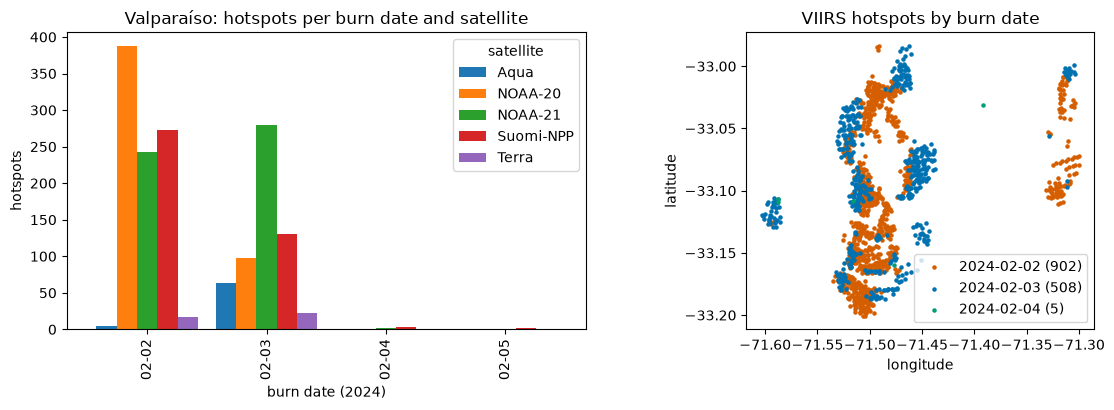

In [8]:
daily = q(f"""
    SELECT burn_date, satellite, count(*) AS n FROM h
    WHERE {area_sql(case)} AND burn_date BETWEEN DATE '{case['window'][0]}' AND DATE '{case['window'][1]}'
    GROUP BY ALL
""").pivot(index="burn_date", columns="satellite", values="n").fillna(0)
points = q(f"""
    SELECT longitude, latitude, burn_date FROM h
    WHERE {area_sql(case)} AND instrument = 'VIIRS' AND burn_date BETWEEN DATE '2024-02-02' AND DATE '2024-02-04'
""")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
daily.index = [str(d)[5:10] for d in daily.index]
daily.plot.bar(ax=ax1, width=0.85)
ax1.set(title="Valparaíso: hotspots per burn date and satellite", xlabel="burn date (2024)", ylabel="hotspots")
for day, colour in [("2024-02-02", "#D55E00"), ("2024-02-03", "#0072B2"), ("2024-02-04", "#009E73")]:
    p = points[points.burn_date.astype(str).str[:10] == day]
    ax2.scatter(p.longitude, p.latitude, s=5, color=colour, label=f"{day} ({len(p)})")
ax2.set(title="VIIRS hotspots by burn date", xlabel="longitude", ylabel="latitude", aspect=1.19)
ax2.legend()
fig.tight_layout()
fig.savefig(ROOT / "docs" / "findings" / "06-valparaiso-2024.png", dpi=130)
plt.show()

## 6.4 Two cases only MODIS saw

The team's case list had no fire from before 2012. These two are the candidates of the plan.
Each shows the raw MODIS count and what the harmonization turns it into.

In [9]:
old = []
for case in CASES[-2:]:
    d0, d1 = case["window"]
    raw = q(f"SELECT count(*) AS n FROM h WHERE {area_sql(case)} AND burn_date BETWEEN DATE '{d0}' AND DATE '{d1}'").n[0]
    harm = q(f"""
        SELECT sum(hotspots_raw) AS raw_cells, sum(hotspots_harmonized) AS harmonized,
               list(DISTINCT sensor) AS sensors FROM c
        WHERE {area_sql(case, 'cell_lat', 'cell_lon', 0.25)} AND burn_date BETWEEN DATE '{d0}' AND DATE '{d1}'
    """).iloc[0]
    old.append({"case": case["name"], "modis_hotspots_in_box": int(raw), "modis_hotspots_in_cells": int(harm.raw_cells),
                "harmonized": round(harm.harmonized), "factor": round(harm.harmonized / harm.raw_cells, 2),
                "sensors_in_series": list(harm.sensors)})
pd.DataFrame(old).set_index("case")

,modis_hotspots_in_box,modis_hotspots_in_cells,harmonized,factor,sensors_in_series
case,,,,,
"Torres del Paine, Dec 2011 - Jan 2012",106,106,552,5.21,[MODIS]
"Paraná Delta, Apr 2008",3754,3763,16203,4.31,[MODIS]
